In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [ ]:
# Load Dataset

In [2]:
train_data = pd.read_csv("fashion-mnist_train.csv")
test_data = pd.read_csv("fashion-mnist_test.csv")

print("Training Shape:", train_data.shape)
print("Testing Shape:", test_data.shape)

Training Shape: (60000, 785)
Testing Shape: (10000, 785)


In [ ]:
# Separate Features and Labels

In [3]:
X_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

X_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

In [ ]:
# Define Class Names

In [4]:
class_names = [
    'T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle Boot'
]

In [ ]:
# Normalize Pixel Values

In [5]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [ ]:
# Reshape Images

In [6]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [ ]:
# Build CNN Model

In [7]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),

    MaxPooling2D(pool_size=(2,2)),

    Conv2D(64, (3,3), activation='relu'),

    MaxPooling2D(pool_size=(2,2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Compile Model

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Display Model Summary

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train Model

In [10]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 37s 73ms/step - accuracy: 0.8022 - loss: 0.5467 - val_accuracy: 0.8632 - val_loss: 0.3870
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step - accuracy: 0.8705 - loss: 0.3604 - val_accuracy: 0.8750 - val_loss: 0.3485
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.8866 - loss: 0.3134 - val_accuracy: 0.8840 - val_loss: 0.3142
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 67ms/step - accuracy: 0.8961 - loss: 0.2853 - val_accuracy: 0.8983 - val_loss: 0.2871
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step - accuracy: 0.9054 - loss: 0.2596 - val_accuracy: 0.8997 - val_loss: 0.2904
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 69ms/step - accuracy: 0.9138 - loss: 0.2370 - val_accuracy: 0.9032 - val_loss: 0.2688
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 348s 827ms/step - accuracy: 0.9180 - loss: 0.2227 - val_accuracy: 0.9012 - val_loss: 0.2874
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 33s 77ms/step - accuracy: 0.9238 - loss: 0.2048 

In [ ]:
# Evaluate Testing Accuracy

In [11]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Testing Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9140 - loss: 0.2331
Testing Accuracy: 91.39999747276306 %


In [ ]:
# Predict Five Test Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step


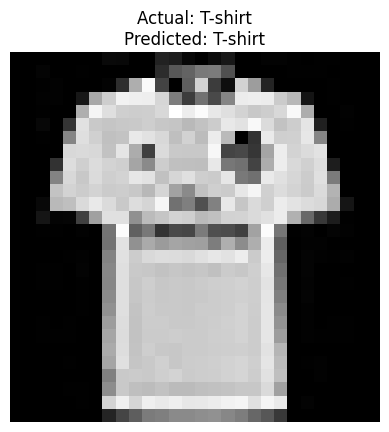

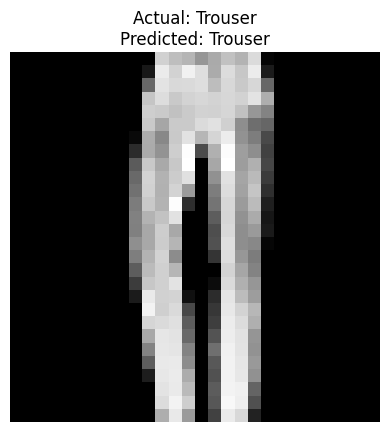

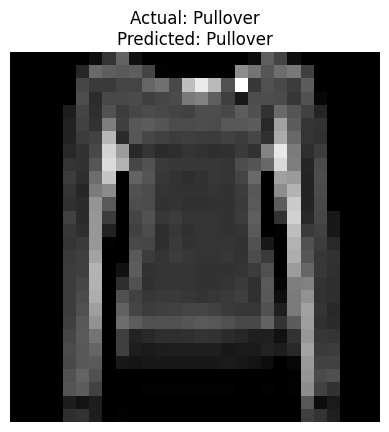

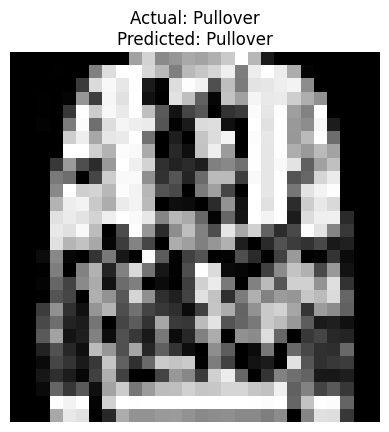

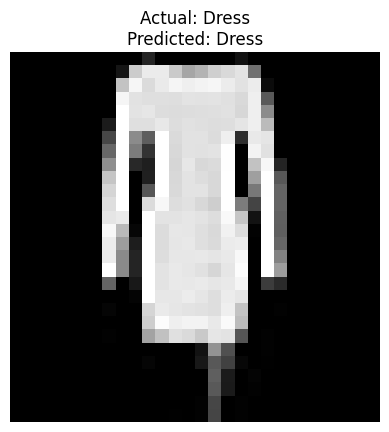

In [12]:
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

for i in range(5):

    plt.imshow(X_test[i].reshape(28,28), cmap='gray')

    plt.title(
        f"Actual: {class_names[y_test[i]]}\n"
        f"Predicted: {class_names[predicted_labels[i]]}"
    )

    plt.axis('off')
    plt.show()

Here are **25 important code-based viva questions with answers** for Practical 18 – CNN using Fashion-MNIST.

## CNN – Fashion-MNIST: 25 Viva Questions

**1. What is Fashion-MNIST?**  
Fashion-MNIST is a dataset containing grayscale images of clothing and footwear items.

**2. How many classes are present in Fashion-MNIST?**  
10 classes.

**3. Name the 10 classes of Fashion-MNIST.**  
T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag and Ankle boot.

**4. Which function is used to load Fashion-MNIST?**  
`fashion_mnist.load_data()`.

**5. How many training and testing images are available?**  
60,000 training images and 10,000 testing images.

**6. What is the size of each image?**  
28 × 28 pixels.

**7. Why do we divide pixel values by 255?**  
To normalize pixel values from 0–255 to 0–1.

**8. Why do we use `reshape(-1, 28, 28, 1)`?**  
To convert images into the CNN input format: height, width and channels. Here, 1 represents grayscale.

**9. What is `Conv2D()`?**  
It is a convolutional layer that extracts features such as edges, shapes and patterns from images.

**10. What does `Conv2D(32, (3,3), activation='relu')` mean?**  
It creates 32 filters of size 3 × 3 with ReLU activation.

**11. What is a filter in CNN?**  
A small matrix that moves over an image to detect important features.

**12. What is the purpose of `MaxPooling2D((2,2))`?**  
It reduces feature-map size by selecting the maximum value from each 2 × 2 region.

**13. What is the difference between Conv2D and MaxPooling2D?**  
Conv2D extracts features, whereas MaxPooling2D reduces the dimensions of feature maps.

**14. What is the purpose of `Flatten()`?**  
It converts 2D feature maps into a 1D vector.

**15. What is a Dense layer?**  
A fully connected layer where each neuron connects to all neurons in the previous layer.

**16. What does `Dense(128, activation='relu')` mean?**  
It creates a hidden layer containing 128 neurons using ReLU activation.

**17. Why do we use `Dense(10, activation='softmax')`?**  
Because Fashion-MNIST has 10 clothing categories. Softmax gives probabilities for each category.

**18. What is the purpose of `model.compile()`?**  
It configures the model with an optimizer, loss function and evaluation metric.

**19. Which optimizer is used in this practical?**  
Adam optimizer, which updates model weights to reduce errors.

**20. Which loss function is used?**  
Sparse categorical crossentropy. It is used for multiclass classification with integer labels.

**21. What is the purpose of `model.fit()`?**  
It trains the CNN model using training images and labels.

**22. What is the purpose of `model.evaluate(X_test, y_test)`?**  
It evaluates the model's performance on testing data.

**23. What does `model.predict(X_test[:5])` do?**  
It predicts the output probabilities for the first five test images.

**24. Why do we use `np.argmax(predictions, axis=1)`?**  
It finds the index of the highest probability for each image, giving the predicted class.

**25. Why do we use `plt.imshow(X_test[i].reshape(28,28), cmap='gray')`?**  
To display a test image in grayscale.

---

### Important code statements to remember

| Code | Purpose |
|---|---|
| `fashion_mnist.load_data()` | Loads Fashion-MNIST |
| `X_train / 255.0` | Normalizes images |
| `reshape(-1,28,28,1)` | Prepares images for CNN |
| `Conv2D()` | Extracts image features |
| `MaxPooling2D()` | Reduces feature-map size |
| `Flatten()` | Converts feature maps into 1D |
| `Dense(128, activation='relu')` | Creates hidden layer |
| `Dense(10, activation='softmax')` | Creates 10 output classes |
| `model.fit()` | Trains the model |
| `model.predict(X_test[:5])` | Predicts five test images |
| `np.argmax()` | Finds predicted class index |
| `plt.imshow()` | Displays test images |

**Important viva point:** Fashion-MNIST and MNIST both contain 28 × 28 grayscale images and 10 classes. However, MNIST classifies handwritten digits, while Fashion-MNIST classifies clothing items.